<a href="https://colab.research.google.com/github/darsanipriya-13/english-to-hinglish-translation/blob/main/copy_of_Copy_of_English_to_Hinglish_Translation_(1)_ipynb_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

# TASK 1: Load and preprocess dataset

import pandas as pd
import re
import random
import numpy as np
import torch
import torch.nn as nn

from google.colab import files
from collections import Counter
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset, DataLoader

uploaded = files.upload()
filename = next(iter(uploaded))

df = pd.read_csv(filename)

# Keep and clean paired sentences
df = df[["english", "hinglish"]].dropna().copy()
df["english"] = df["english"].astype(str).str.strip()
df["hinglish"] = df["hinglish"].astype(str).str.strip()
df = df[(df["english"] != "") & (df["hinglish"] != "")]
df = df.drop_duplicates().reset_index(drop=True)

print("Dataset loaded successfully!")
print("Total sentence pairs:", len(df))
display(df.head(10))


Saving english_hinglish_roman_dataset.csv to english_hinglish_roman_dataset.csv
Dataset loaded successfully!
Total sentence pairs: 191


,english,hinglish
0,Hello,Namaste
1,"Hi, how are you?","Hi, tum kaise ho?"
2,How are you?,Tum kaise ho?
3,I am fine.,Main theek hoon.
4,"I am fine, thank you.","Main theek hoon, shukriya."
5,What is your name?,Tumhara naam kya hai?
6,My name is Ravi.,Mera naam Ravi hai.
7,Nice to meet you.,Tumse milkar achha laga.
8,Good morning.,Suprabhat.
9,Good night.,Shubh ratri.


In [ ]:

# Split into training, validation and test sets

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

train_df, temp_df = train_test_split(
    df, test_size=0.20, random_state=SEED
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=SEED
)

# Word-level tokenization
def tokenize(text):
    return re.findall(r"\w+|[^\w\s]", str(text).lower())

PAD, UNK, BOS, EOS = "<pad>", "<unk>", "<bos>", "<eos>"
SPECIALS = [PAD, UNK, BOS, EOS]
MAX_LEN = 30

def build_vocab(sentences):
    counter = Counter()
    for sentence in sentences:
        counter.update(tokenize(sentence))

    vocab = {word: i for i, word in enumerate(SPECIALS)}
    for word, _ in counter.most_common():
        if word not in vocab:
            vocab[word] = len(vocab)
    return vocab

# Build vocabularies from training data only
src_vocab = build_vocab(train_df["english"])
tgt_vocab = build_vocab(train_df["hinglish"])

PAD_SRC = src_vocab[PAD]
PAD_TGT = tgt_vocab[PAD]
BOS_ID = tgt_vocab[BOS]
EOS_ID = tgt_vocab[EOS]

def encode(text, vocab, target=False):
    tokens = tokenize(text)
    if target:
        tokens = [BOS] + tokens
    tokens = tokens[:MAX_LEN - 1]
    tokens.append(EOS)
    return [vocab.get(t, vocab[UNK]) for t in tokens]

class TranslationData(Dataset):
    def __init__(self, frame):
        self.frame = frame.reset_index(drop=True)

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, idx):
        row = self.frame.iloc[idx]
        src = encode(row["english"], src_vocab)
        tgt = encode(row["hinglish"], tgt_vocab, target=True)
        return torch.tensor(src), torch.tensor(tgt)

def collate_fn(batch):
    src, tgt = zip(*batch)
    lengths = torch.tensor([len(x) for x in src])
    src = nn.utils.rnn.pad_sequence(
        src, batch_first=True, padding_value=PAD_SRC
    )
    tgt = nn.utils.rnn.pad_sequence(
        tgt, batch_first=True, padding_value=PAD_TGT
    )
    return src, lengths, tgt

BATCH_SIZE = 16

train_loader = DataLoader(
    TranslationData(train_df), batch_size=BATCH_SIZE,
    shuffle=True, collate_fn=collate_fn
)
val_loader = DataLoader(
    TranslationData(val_df), batch_size=BATCH_SIZE,
    shuffle=False, collate_fn=collate_fn
)
test_loader = DataLoader(
    TranslationData(test_df), batch_size=BATCH_SIZE,
    shuffle=False, collate_fn=collate_fn
)

print("Training pairs:", len(train_df))
print("Validation pairs:", len(val_df))
print("Test pairs:", len(test_df))
print("English vocabulary:", len(src_vocab))
print("Hinglish vocabulary:", len(tgt_vocab))


Device: cuda
Training pairs: 152
Validation pairs: 19
Test pairs: 20
English vocabulary: 266
Hinglish vocabulary: 300


In [ ]:

# TASK 3: LSTM Encoder-Decoder

class Encoder(nn.Module):
    def __init__(self, vocab_size, emb_dim, hidden_dim):
        super().__init__()
        self.embedding = nn.Embedding(
            vocab_size, emb_dim, padding_idx=PAD_SRC
        )
        self.lstm = nn.LSTM(
            emb_dim, hidden_dim, batch_first=True
        )

    def forward(self, src, lengths):
        embedded = self.embedding(src)
        packed = nn.utils.rnn.pack_padded_sequence(
            embedded, lengths.cpu(), batch_first=True,
            enforce_sorted=False
        )
        _, (hidden, cell) = self.lstm(packed)
        return hidden, cell


class Decoder(nn.Module):
    def __init__(self, vocab_size, emb_dim, hidden_dim):
        super().__init__()
        self.embedding = nn.Embedding(
            vocab_size, emb_dim, padding_idx=PAD_TGT
        )
        self.lstm = nn.LSTM(
            emb_dim, hidden_dim, batch_first=True
        )
        self.fc = nn.Linear(hidden_dim, vocab_size)

    def forward(self, token, hidden, cell):
        embedded = self.embedding(token)
        output, (hidden, cell) = self.lstm(
            embedded, (hidden, cell)
        )
        return self.fc(output.squeeze(1)), hidden, cell


class Seq2Seq(nn.Module):
    def __init__(self, encoder, decoder):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder

    def forward(self, src, lengths, tgt, teacher_forcing=0.5):
        batch_size, target_len = tgt.shape
        outputs = torch.zeros(
            batch_size, target_len, len(tgt_vocab), device=device
        )

        hidden, cell = self.encoder(src, lengths)
        token = tgt[:, 0].unsqueeze(1)

        for t in range(1, target_len):
            prediction, hidden, cell = self.decoder(
                token, hidden, cell
            )
            outputs[:, t] = prediction

            if random.random() < teacher_forcing:
                token = tgt[:, t].unsqueeze(1)
            else:
                token = prediction.argmax(1).unsqueeze(1)

        return outputs


EMB_DIM = 64
HIDDEN_DIM = 128

model = Seq2Seq(
    Encoder(len(src_vocab), EMB_DIM, HIDDEN_DIM),
    Decoder(len(tgt_vocab), EMB_DIM, HIDDEN_DIM)
).to(device)

print(model)


Seq2Seq(
  (encoder): Encoder(
    (embedding): Embedding(266, 64, padding_idx=0)
    (lstm): LSTM(64, 128, batch_first=True)
  )
  (decoder): Decoder(
    (embedding): Embedding(300, 64, padding_idx=0)
    (lstm): LSTM(64, 128, batch_first=True)
    (fc): Linear(in_features=128, out_features=300, bias=True)
  )
)


In [ ]:

# TASK 4: Train the model

optimizer = torch.optim.Adam(model.parameters(), lr=0.003)
criterion = nn.CrossEntropyLoss(ignore_index=PAD_TGT)

def run_epoch(loader, training=True):
    model.train() if training else model.eval()
    total_loss = 0
    total_tokens = 0

    for src, lengths, tgt in loader:
        src, tgt = src.to(device), tgt.to(device)

        if training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(training):
            outputs = model(
                src, lengths, tgt,
                teacher_forcing=0.5 if training else 0.0
            )

            logits = outputs[:, 1:, :].reshape(-1, len(tgt_vocab))
            targets = tgt[:, 1:].reshape(-1)
            loss = criterion(logits, targets)

            if training:
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()

        count = (targets != PAD_TGT).sum().item()
        total_loss += loss.item() * count
        total_tokens += count

    return total_loss / max(total_tokens, 1)


EPOCHS = 60
train_losses, val_losses = [], []

for epoch in range(EPOCHS):
    tr_loss = run_epoch(train_loader, True)
    va_loss = run_epoch(val_loader, False)

    train_losses.append(tr_loss)
    val_losses.append(va_loss)

    if (epoch + 1) % 5 == 0:
        print(
            f"Epoch {epoch+1}/{EPOCHS} | "
            f"Train Loss: {tr_loss:.4f} | "
            f"Validation Loss: {va_loss:.4f}"
        )

print("Training completed!")


Epoch 5/60 | Train Loss: 3.4459 | Validation Loss: 4.2646
Epoch 10/60 | Train Loss: 2.6021 | Validation Loss: 4.3519
Epoch 15/60 | Train Loss: 1.8444 | Validation Loss: 4.6000
Epoch 20/60 | Train Loss: 1.0055 | Validation Loss: 5.0645
Epoch 25/60 | Train Loss: 0.4189 | Validation Loss: 5.3117
Epoch 30/60 | Train Loss: 0.1932 | Validation Loss: 5.3838
Epoch 35/60 | Train Loss: 0.1057 | Validation Loss: 5.7373
Epoch 40/60 | Train Loss: 0.0667 | Validation Loss: 5.7831
Epoch 45/60 | Train Loss: 0.0469 | Validation Loss: 5.9307
Epoch 50/60 | Train Loss: 0.0354 | Validation Loss: 6.0345
Epoch 55/60 | Train Loss: 0.0277 | Validation Loss: 6.1043
Epoch 60/60 | Train Loss: 0.0225 | Validation Loss: 6.2129
Training completed!


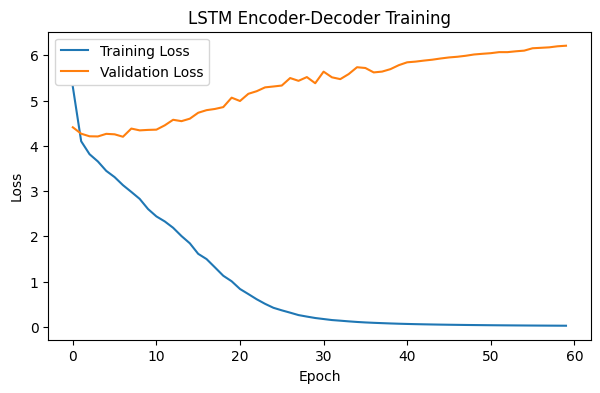

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("LSTM Encoder-Decoder Training")
plt.legend()
plt.show()


In [ ]:

# English sentence -> Roman Hinglish

id_to_tgt = {i: word for word, i in tgt_vocab.items()}

def translate(sentence):
    model.eval()

    src_ids = encode(sentence, src_vocab)
    src_tensor = torch.tensor(
        [src_ids], dtype=torch.long, device=device
    )
    lengths = torch.tensor([len(src_ids)])

    result = []

    with torch.no_grad():
        hidden, cell = model.encoder(src_tensor, lengths)
        token = torch.tensor([[BOS_ID]], device=device)

        for _ in range(MAX_LEN):
            logits, hidden, cell = model.decoder(
                token, hidden, cell
            )
            next_id = logits.argmax(1).item()

            if next_id == EOS_ID:
                break

            if next_id not in (PAD_TGT, tgt_vocab[UNK], BOS_ID):
                result.append(id_to_tgt[next_id])

            token = torch.tensor([[next_id]], device=device)

    text = " ".join(result)
    text = re.sub(r"\s+([.,!?;:])", r"\1", text)
    return text


# Test one sentence
print("English: How are you?")
print("Hinglish:", translate("How are you?"))


English: How are you?
Hinglish: tum kaise ho?


In [ ]:

!pip -q install sacrebleu


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.8/100.8 kB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.7/129.7 kB 13.6 MB/s eta 0:00:00


In [ ]:

from sacrebleu.metrics import BLEU

references = test_df["hinglish"].tolist()
predictions = [translate(s) for s in test_df["english"].tolist()]

bleu = BLEU().corpus_score(predictions, [references])

print(f"Test BLEU Score: {bleu.score:.2f}")
print("Number of test sentences:", len(test_df))


Test BLEU Score: 3.62
Number of test sentences: 20


In [ ]:

# TASK 5: Interactive English-to-Hinglish translation

while True:
    user_input = input(
        "\nEnter an English sentence (type 'exit' to stop): "
    )

    if user_input.strip().lower() == "exit":
        print("Translation stopped.")
        break

    if not user_input.strip():
        print("Please enter a sentence.")
        continue

    output = translate(user_input)

    print("English Input :", user_input)
    print("Hinglish Output:", output)



Enter an English sentence (type 'exit' to stop): hi,how are u ??
English Input : hi,how are u ??
Hinglish Output: hi, tum kaise ho?

Enter an English sentence (type 'exit' to stop): exit
Translation stopped.


In [ ]:

test_sentences = [
    "How are you today?",
    "What is your name?",
    "I am going to school.",
    "Please help me with this work.",
    "I want to learn something new."
]

for sentence in test_sentences:
    print("English :", sentence)
    print("Hinglish:", translate(sentence))
    print("-" * 40)


English : How are you today?
Hinglish: tum kaise ho?
----------------------------------------
English : What is your name?
Hinglish: tumhari favourite movie kaunsi hai?
----------------------------------------
English : I am going to school.
Hinglish: main school ja raha hoon.
----------------------------------------
English : Please help me with this work.
Hinglish: please mujhe thoda paani do.
----------------------------------------
English : I want to learn something new.
Hinglish: main apni communication improve karna chahta hoon.
----------------------------------------
